# **Malaria Detection**

#<b>Problem Definition</b>
##<b>The context<b>:
Malaria is an infectious disease caused by Plasmodium parasites. These parasites are transmitted by mosquitos and can prove life-threatening if not properly diagnosed.

##<b>Objectives<b>:
Our objective is to classify images from the dataset which present Plasmodium infected cells by using Convolutional Neural Networks. We will test various models of different complexity and eventualy decide wich one that is giving us the best performance.

##<b>The key questions:<b>
*  What distinguish the two categories?
*  Wich technique or set of techniques yield the best results ?
*  Does complexity of the model improve predictions ?

##<b>Problem formulation<b>:
We are trying to distinguish uninfected cells from parasitized one by using CNN models in order for patients suffering from Malaria to treat them.

## <b>Data Description </b>

There are a total of 24,958 train and 2,600 test images (colored) that we have taken from microscopic images. These images are of the following categories:<br>


**Parasitized:** The parasitized cells contain the Plasmodium parasite which causes malaria<br>
**Uninfected:** The uninfected cells are free of the Plasmodium parasites<br>


###<b> Mount the Drive

In [ ]:
from google.colab import drive  #Import "drive" module to mount drive
drive.mount('/content/drive')   #Mount drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### <b>Loading libraries</b>

In [ ]:
#Import library to load the datafile
import zipfile
import os
#Import module to read images
from PIL import Image
#Import library for image processing
import cv2
#Import libraries for data preparation & plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#Deactivate warnings
import warnings
warnings.simplefilter("ignore")
#Renders plots in the nodebook
%matplotlib inline

### <b>Let us load the data</b>

**Note:**
- You must download the dataset from the link provided on Olympus and upload the same to your Google Drive. Then unzip the folder.

In [ ]:
#Define zipfile path
datapath =  '/content/drive/MyDrive/trainings/MIT/notebook/capstone_project/cell_images.zip'
#Extract files
with zipfile.ZipFile(datapath, 'r') as zip:
  zip.extractall()

The extracted folder has different folders for train and test data will contain the different sizes of images for parasitized and uninfected cells within the respective folder name.

The size of all images must be the same and should be converted to 4D arrays so that they can be used as an input for the convolutional neural network. Also, we need to create the labels for both types of images to be able to train and test the model.

Let's do the same for the training data first and then we will use the same code for the test data as well.

In [ ]:
#Storing training and test folders path
path = '/content/cell_images'

#Defining a pixel size variable to set common size to all the images of the dataset
px_size = 64

#Create empty list to store the images
training_img_data = []
training_labels = []
test_img_data = []
test_labels = []

#Create a list with the name of the folders to loop through
directories = ['/train/', '/test/']
folders = ['/parasitized/', '/uninfected/']

#Loop through directories
for dir in directories:
  #Loop through folders
  for folder in folders:
    #Define the path of the image
    images_path = os.listdir(path + dir + folder)
    #Loop through images
    for i in images_path:
      #Open image file
      img = Image.open(path + dir + folder + i)
      #Resize image using previously set pixel size variable
      img = img.resize((px_size, px_size))
      #Convert the image to an Numpy array
      img = np.array(img)
      #Set labels and images to the correct list based on the folder's name for training dataset
      if dir == '/train/':
        training_img_data.append(img)
        if folder == '/parasitized/':
          training_labels.append(1)
        else:
          training_labels.append(0)
      #Set labels and images to the correct list based on the folder's name for test dataset
      else:
        test_img_data.append(img)
        if folder == '/parasitized/':
          test_labels.append(1)
        else:
          test_labels.append(0)

#Convert the result list to Numpy array
training_img_data = np.array(training_img_data)
test_img_data = np.array(test_img_data)
training_labels = np.array(training_labels)
test_labels = np.array(test_labels)

###<b> Check the shape of train and test images

In [ ]:
training_img_data.shape, test_img_data.shape

((24958, 64, 64, 3), (2600, 64, 64, 3))

###<b> Check the shape of train and test labels

In [ ]:
training_labels.shape, test_labels.shape

((24958,), (2600,))

####<b> Observations and insights: _____
*   The dataset is comprised of 27,558 images
*   The training dataset represent ~90% of the entire available data
*   The images dataset are now 4D array
*   The labels are converted to 1D array
*   The image are all resized to 64 by 64 pixels

### <b>Check the minimum and maximum range of pixel values for train and test images

In [ ]:
print("Min training set pixel's value = " + str(training_img_data.min()))
print("Max training set pixel's value = " + str(training_img_data.max()))
print("\nMin test set pixel's value = " + str(test_img_data.min()))
print("Max test set pixel's value = " + str(test_img_data.max()))

Min training set pixel's value = 0
Max training set pixel's value = 255

Min test set pixel's value = 0
Max test set pixel's value = 255


####<b> Observations and insights: _____

*   The images' pixel values of both sets are contained in a range of 0 to 255

###<b> Count the number of values in both uninfected and parasitized

In [ ]:
# Count the number of values in both uninfected and parasitized for training data
train_counts = np.bincount(training_labels)
print("Training data counts:")
print(f"Uninfected: {train_counts[0]}")
print(f"Parasitized: {train_counts[1]}")

# Count the number of values in both uninfected and parasitized for test data
test_counts = np.bincount(test_labels)
print("\nTest data counts:")
print(f"Uninfected: {test_counts[0]}")
print(f"Parasitized: {test_counts[1]}")

Training data counts:
Uninfected: 12376
Parasitized: 12582

Test data counts:
Uninfected: 1300
Parasitized: 1300


###<b>Normalize the images

In [ ]:
training_img_data = (training_img_data / 255).astype('float32')
test_img_data = (test_img_data / 255).astype('float32')

####<b> Observations and insights: _____


*   There is 12,376 images of uninfected cells by malaria in the train data
*   There is 12,582 images of paratized cells by malaria in the train data
*   There is 1,300 images for each categories in the test data set for
*   The images are now normalized

###<b> Plot to check if the data is balanced

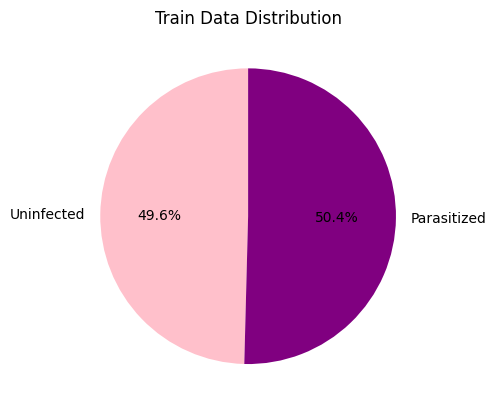

In [ ]:
#Plot for the categories using pie chart
plt.pie(train_counts, labels=['Uninfected', 'Parasitized'], autopct='%1.1f%%', colors=['pink', 'purple'], startangle=90)
plt.title('Train Data Distribution')
plt.show()

####<b> Observations and insights: _____



*   There images of *uninfected* cells represent 49.6% of the training set
*   There images of *parasitized* cells represent 50.4% of the training set
*   The data is balanced with ~50/50% distribution



### <b>Data Exploration</b>
Let's visualize the images from the train data

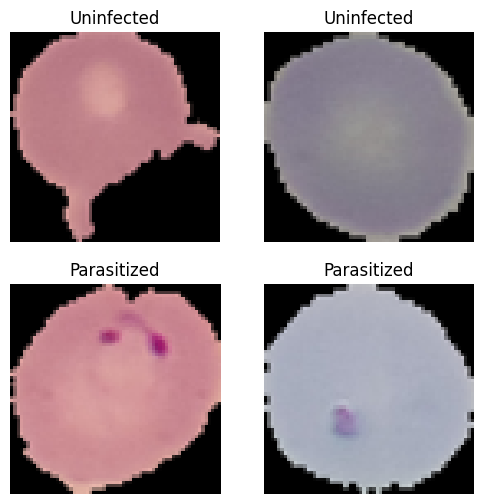

In [ ]:
#Setting seed
np.random.seed(42)
#Set plot dimensions
plt.figure(figsize=(6, 6))
#Randomly show 2 images for each category from the dataset
for i in range(4):
  #Choose random index
  index = int(np.random.randint(0, training_labels.shape[0], 1))
  #Define plot's dimensions
  plt.subplot(2,2, i + 1)
  plt.imshow(training_img_data[index])
  #Define caption accordingly to the image using id
  plt.title('Parasitized' if training_labels[index] else "Uninfected")
  plt.axis('off')
plt.show()

####<b> Observations and insights: _____



*   Uninfincted images pocess less color variation and constrast than Parasatized one
*   Parazatized images are composed of mostly redish color with purple area
*   The model could be faster using the red or the blue channel only rather than the three channel



###<b> Visualize the images with subplot(6, 6) and figsize = (12, 12)

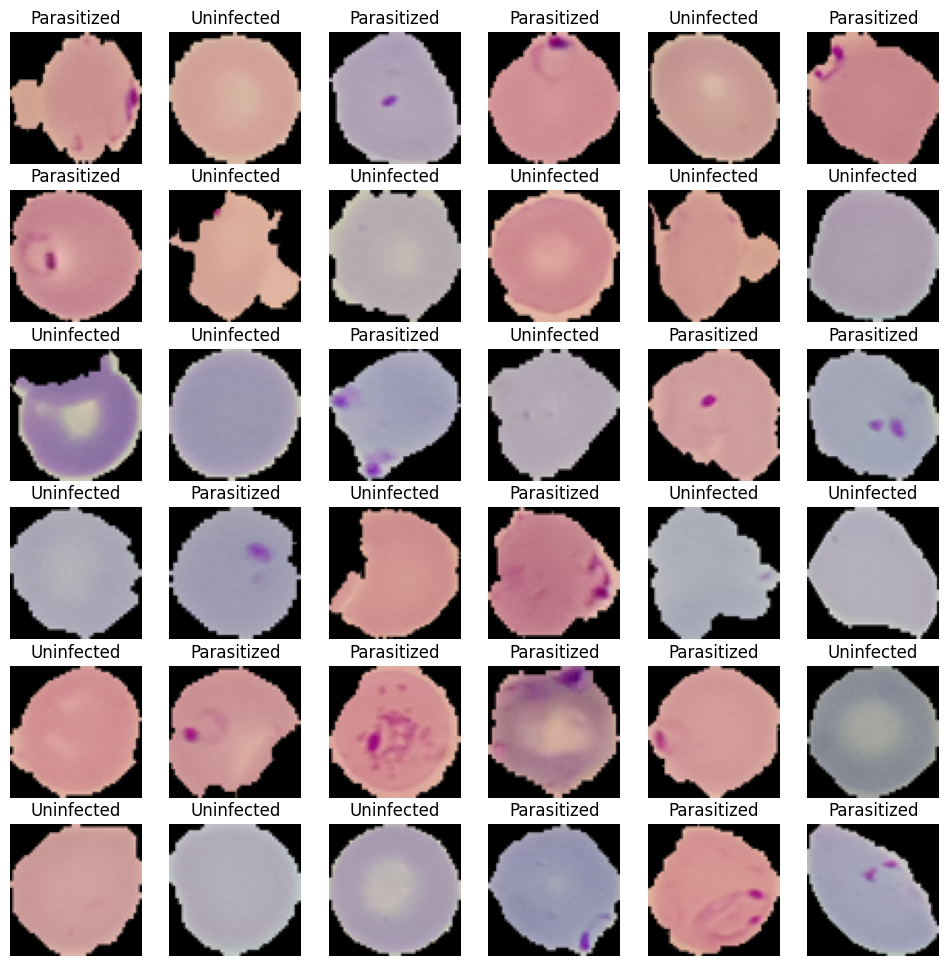

In [ ]:
#Setting seed
np.random.seed(16)
#Set plot dimensions
plt.figure(figsize=(12, 12))
#Randomly show 36 images for each category from the dataset
for i in range(36):
  #Compute random index
  index = int(np.random.randint(0, training_labels.shape[0], 1))
  #Define plot shape
  plt.subplot(6,6, i + 1)
  #Show image
  plt.imshow(training_img_data[index])
  #Show caption accordingly to the images index
  plt.title('Parasitized' if training_labels[index] else "Uninfected")
  plt.axis('off')
plt.show()

####<b>Observations and insights:



*   The range of color variation of the Parasatized's cells images is broader than previously observed
*   Contrast is not as steady as notice before for the Uninfected's cells images
*   Saturation level seems a good variable to distinguish the two categories
*   The image values appears to be more significant in the red and blue channels
*   Parazitized images contains shapes ranging from dots and circles to more diffuse shapes


###<b> Plotting the mean images for parasitized and uninfected

In [ ]:
#Function to plot an image of the mean pixel values for a given category
def mean_image_plot(image_data, label):
  #Define index variable based on given category
  id = 1 if label=='Parasitized' else 0
  #Compute mean pixel values
  mean_img = np.mean(image_data[training_labels == id], axis=0)
  #Show image
  plt.imshow(mean_img)
  #Define image caption
  plt.title('Mean ' + label + ' Image')
  plt.axis('off')
  plt.show()

<b> Mean image for parasitized

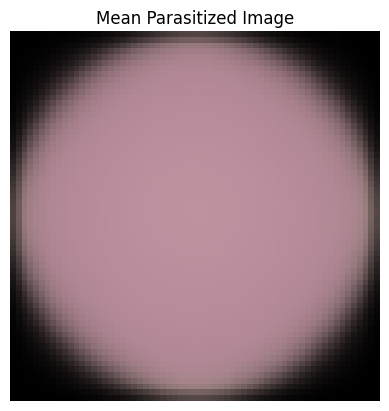

In [ ]:
mean_image_plot(training_img_data, 'Parasitized')

<b> Mean image for uninfected

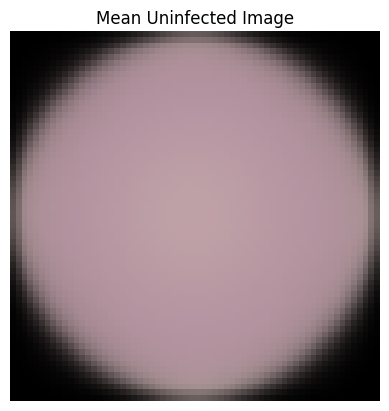

In [ ]:
mean_image_plot(training_img_data, 'Uninfected')

####<b> Observations and insights: _____


*   Both mean images are of the same circular shape
*   Mean image for the *Parasitized* cells is slightly more saturated



### <b>Converting RGB to HSV of Images using OpenCV

###<b> Converting the train data

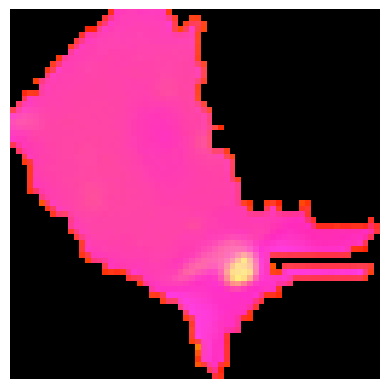

In [ ]:
#Create empty list to store the converted image
train_hsv=[]
#Convert the train data
for i in np.arange(0, training_img_data.shape[0], 1):
  to_hsv = cv2.cvtColor(training_img_data[i], cv2.COLOR_BGR2HSV)
  train_hsv.append(to_hsv)
#Convert the list to a Numpy array
train_hsv = np.array(train_hsv)
#Show a sample image of the converted data
plt.imshow(train_hsv[1])
plt.axis('off')
plt.show()

###<b> Converting the test data

In [ ]:
#Create empty list to store the converted image
test_hsv=[]
#Convert the test data
for i in np.arange(0, test_img_data.shape[0], 1):
  to_hsv = cv2.cvtColor(test_img_data[i], cv2.COLOR_BGR2HSV)
  test_hsv.append(to_hsv)
#Convert the list to a Numpy array
test_hsv = np.array(test_hsv)

####<b>Observations and insights: _____

*  Once converted to HSV the feature are more obvious
*  The features are now visible on differents channels

###<b> Processing Images using Gaussian Blurring

###<b> Gaussian Blurring on train data

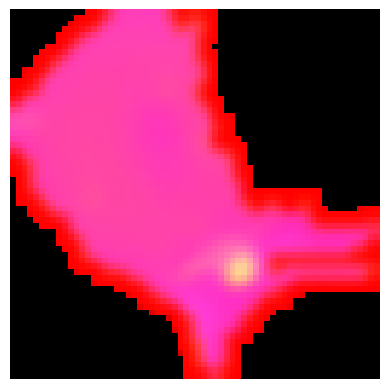

In [ ]:
#Create empty list to store the converted image
train_blur = []
for i in np.arange(0, training_img_data.shape[0], 1):
  blurred = cv2.GaussianBlur(train_hsv[i], (5, 5), 0)
  train_blur.append(blurred)
#Convert to Numpy array
train_blur = np.array(train_blur)
#Show a sample image of the converted data
plt.imshow(train_blur[1])
plt.axis('off')
plt.show()

###<b> Gaussian Blurring on test data

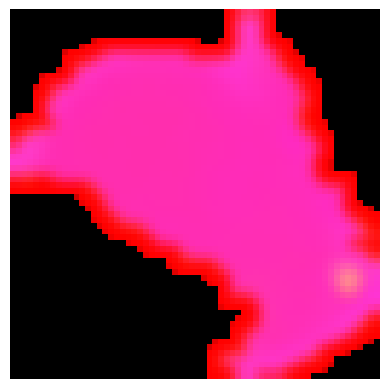

In [ ]:
#Create empty list to store the converted image
test_blur = []
#Loop through image to apply blur
for i in np.arange(0, test_img_data.shape[0], 1):
  blurred = cv2.GaussianBlur(test_hsv[i], (5, 5), 0)
  #Add image to the list
  test_blur.append(blurred)
test_blur = np.array(test_blur)
#Show a sample image of the converted data
plt.imshow(test_blur[1])
plt.axis('off')
plt.show()

####**Observations and insights: _____**
*  Blurred images show bigger features wich could prove to be easier to identify
*  Subtle color variation that could be falsely interpreted as parasitized could be nudge into the surrounding close value
*  If dialed with a high value blur could proove detrimental to some key details
*  Other type of blur could be more interesting
*  Blur effectiveness will vary with change in resolution

**Think About It:** Would blurring help us for this problem statement in any way? What else can we try?

## **Model Building**

### **Base Model**




###<b> Importing the required libraries for building and training our Model

In [ ]:
#Import libraries and modules for the ANN and CNN models
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, BatchNormalization, Flatten, Conv2D, MaxPooling2D, LeakyReLU
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from tensorflow.keras import backend

####<B>One Hot Encoding the train and test labels

In [ ]:
training_labels = to_categorical(training_labels)
test_labels = to_categorical(test_labels)

###<b> Building the model

In [ ]:
#Create an instance of the model
base_model = Sequential()
#First convolution layer
base_model.add(Conv2D(16, (3, 3), input_shape=(64, 64, 3), activation='relu'))
#Second convolution layer
base_model.add(Conv2D(16, (3, 3), input_shape=(64, 64, 3), activation='relu'))
#Max Pooling layer
base_model.add(MaxPooling2D(pool_size=(2, 2)))
#Reshape data for dense layer
base_model.add(Flatten())
#Dense Network
base_model.add(Dense(16, activation='relu'))
base_model.add(LeakyReLU(alpha=0.1))
base_model.add(Dense(2, activation='softmax'))

###<b> Compiling the model

In [ ]:
base_model.compile(optimizer=Adam(learning_rate = 0.001), loss='categorical_crossentropy', metrics=['accuracy'])

<b> Using Callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 2),
             ModelCheckpoint('best_model.keras', monitor = 'val_loss', save_best_only = True)]

<b> Fit and train our Model

In [ ]:
base_model.summary()
fit_history_base_model = base_model.fit(training_img_data, training_labels, validation_split=0.2, verbose=1, epochs=20, batch_size=64, callbacks=callbacks)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 60, 60, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │       230,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 233,218 (911.01 KB)

 Trainable params: 233,218 (911.01 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.6367 - loss: 0.6448 - val_accuracy: 0.2806 - val_loss: 0.9042
Epoch 2/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7324 - loss: 0.5558 - val_accuracy: 0.8474 - val_loss: 0.5847
Epoch 3/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8793 - loss: 0.3428 - val_accuracy: 0.9728 - val_loss: 0.2682
Epoch 4/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9353 - loss: 0.1793 - val_accuracy: 0.9690 - val_loss: 0.1925
Epoch 5/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9545 - loss: 0.1309 - val_accuracy: 0.9669 - val_loss: 0.1204
Epoch 6/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9668 - loss: 0.0906 - val_accuracy: 0.9393 - val_loss: 0.2309
Epoch 7/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9707 - loss: 0.0819 - val_accuracy: 0.9681 - val_loss: 0.1220


###<b> Evaluating the model on test data

In [ ]:
test_pred = base_model.predict(test_img_data)
test_pred = np.argmax(test_pred, axis = -1)

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


<b> Plotting the confusion matrix

              precision    recall  f1-score   support

           0       0.97      0.95      0.96      1300
           1       0.95      0.97      0.96      1300

    accuracy                           0.96      2600
   macro avg       0.96      0.96      0.96      2600
weighted avg       0.96      0.96      0.96      2600



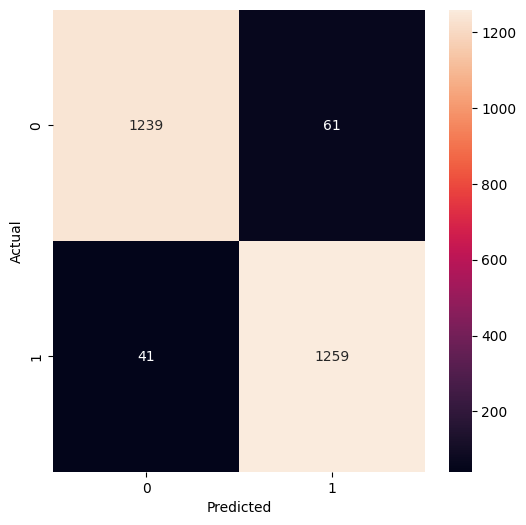

In [ ]:
#Print classification metrics to read the performances values
print(classification_report(np.argmax(test_labels, axis=-1), test_pred))
#Compute confusion matrix
cm = confusion_matrix(np.argmax(test_labels, axis=-1), test_pred)
#Define the plot sise
plt.figure(figsize=(6, 6))
#Plot the confusion matrix
sns.heatmap(cm, annot = True,  fmt = 'd',)
#Define the axis' labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
#Show plot
plt.show()

<b>Plotting the train and validation curves

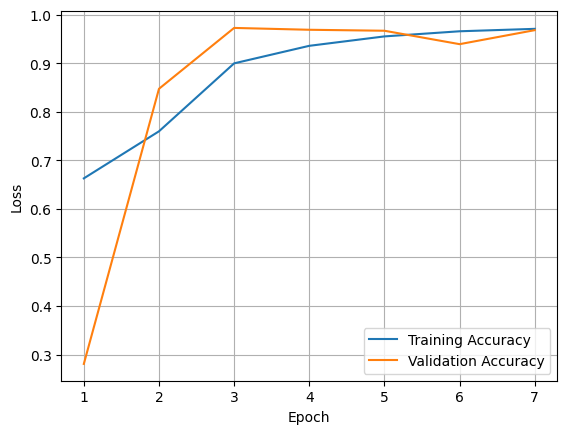

In [ ]:
#Store model history
dict_history_base_model = fit_history_base_model.history
#Define a range of value corresponding to the model's numbers of epoch
epoch_number = range(1, len(dict_history_base_model['accuracy']) + 1)
#Plot training accuracy
plt.plot(epoch_number, dict_history_base_model['accuracy'], label = 'Training Accuracy')
#Plot validation accuracy
plt.plot(epoch_number, dict_history_base_model['val_accuracy'], label = 'Validation Accuracy')
#Create a grid for better value reading
plt.grid()
#Define axis labels
plt.xlabel('Epoch')
plt.ylabel('Loss')
#Show legend
plt.legend()
#Show plot
plt.show()

So now let's try to build another model with few more add on layers and try to check if we can try to improve the model. Therefore try to build a model by adding few layers if required and altering the activation functions.

###<b> Model 1
####<b> Trying to improve the performance of our model by adding new layers


In [ ]:
backend.clear_session()

###<b> Building the Model

In [ ]:
#Create an instance of the model
model1 = Sequential()
#First convolution layer
model1.add(Conv2D(16, (3, 3), input_shape=(64, 64, 3), activation='relu'))
#Dropout
model1.add(Dropout(0.2))
#Second convolution layer
model1.add(Conv2D(8, (3, 3), input_shape=(64, 64, 3), activation='relu'))
#Third convolution layer
model1.add(Conv2D(4, (3, 3), input_shape=(64, 64, 3), activation='relu'))
#Max Pooling layer
model1.add(MaxPooling2D(pool_size=(2, 2)))
#Reshape data for dense layer
model1.add(Flatten())

#Dense Network
#First dense layer
model1.add(Dense(32, activation='relu'))
#Second dense layer
model1.add(Dense(16, activation='relu'))
#Output layer
model1.add(Dense(2, activation='softmax'))

###<b> Compiling the model

In [ ]:
model1.compile(optimizer=Adam(learning_rate = 0.001), loss='categorical_crossentropy', metrics=['accuracy'])

<b> Using Callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 2),
             ModelCheckpoint('best_model.keras', monitor = 'val_loss', save_best_only = True)]

<b>Fit and Train the model

In [ ]:
#Print model's summary
model1.summary()
#Fit the model
fit_history_model1 = model1.fit(training_img_data, training_labels, validation_split=0.2, verbose=1, epochs=20, batch_size=64, callbacks=callbacks)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 62, 62, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 60, 60, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 58, 58, 4)      │           292 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 29, 29, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3364)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       107,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,142 (430.24 KB)

 Trainable params: 110,142 (430.24 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.6435 - loss: 0.6406 - val_accuracy: 0.9275 - val_loss: 0.3766
Epoch 2/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9077 - loss: 0.2596 - val_accuracy: 0.9551 - val_loss: 0.3091
Epoch 3/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9375 - loss: 0.1842 - val_accuracy: 0.9301 - val_loss: 0.1628
Epoch 4/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9468 - loss: 0.1485 - val_accuracy: 0.9269 - val_loss: 0.1642
Epoch 5/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9544 - loss: 0.1313 - val_accuracy: 0.9609 - val_loss: 0.1623
Epoch 6/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9595 - loss: 0.1176 - val_accuracy: 0.9665 - val_loss: 0.1224
Epoch 7/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.9637 - loss: 0.1089 - val_accuracy: 0.9433 - val_loss: 0.1637
Epoch 8/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9657 - loss: 0.0976 - val_accuracy:

###<b> Evaluating the model

In [ ]:
test_pred_model1 = model1.predict(test_img_data)
test_pred_model1 = np.argmax(test_pred_model1, axis = -1)

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


<b> Plotting the confusion matrix

              precision    recall  f1-score   support

           0       0.99      0.93      0.96      1300
           1       0.94      0.99      0.96      1300

    accuracy                           0.96      2600
   macro avg       0.96      0.96      0.96      2600
weighted avg       0.96      0.96      0.96      2600



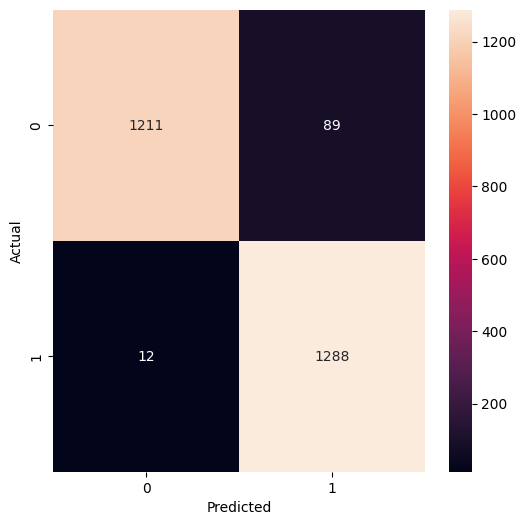

In [ ]:
#Print performance metrics
print(classification_report(np.argmax(test_labels, axis=-1), test_pred_model1))
#Compute confusion matrix
cm = confusion_matrix(np.argmax(test_labels, axis=-1), test_pred_model1)
#Define plot size
plt.figure(figsize=(6, 6))
#Plot confusion matrix
sns.heatmap(cm, annot = True,  fmt = 'd',)
#Define the axis' labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
#Show plot
plt.show()

<b> Plotting the train and the validation curves

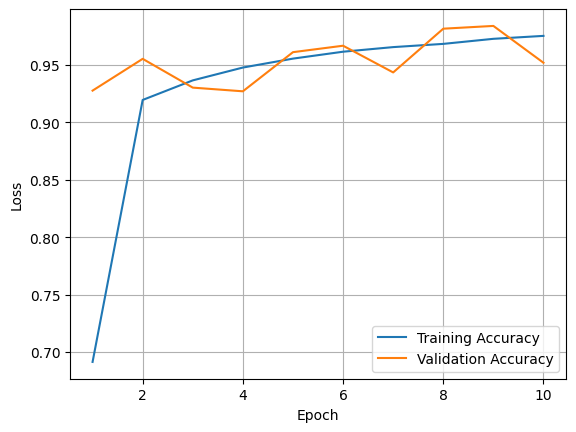

In [ ]:
#Store the model accuracy history
dict_history_model1 = fit_history_model1.history
#Create a range of value for the x axis coherent to the number of epoch of the model
epoch_number = range(1, len(dict_history_model1['accuracy']) + 1)
#Plot training accuracy
plt.plot(epoch_number, dict_history_model1['accuracy'], label = 'Training Accuracy')
#Plot validation accuracy
plt.plot(epoch_number, dict_history_model1['val_accuracy'], label = 'Validation Accuracy')
#Create grid
plt.grid()
#Create axis' labels
plt.xlabel('Epoch')
plt.ylabel('Loss')
#Create legend
plt.legend()
#Show plot
plt.show()

###<b>Think about it:</b><br>
Now let's build a model with LeakyRelu as the activation function  

*  Can the model performance be improved if we change our activation function to LeakyRelu?
*  Can BatchNormalization improve our model?

Let us try to build a model using BatchNormalization and using LeakyRelu as our activation function.

###<b> Model 2 with Batch Normalization

In [ ]:
backend.clear_session()

###<b> Building the Model

In [ ]:
#Create an instance of the model
model2 = Sequential()
#First convolution layer
model2.add(Conv2D(16, (3, 3), input_shape=(64, 64, 3)))
#LeakyRelu activation
model2.add(LeakyReLU(alpha=0.1))
#Normalization layer
model2.add(BatchNormalization())
#Dropout
model2.add(Dropout(0.2))
#Second convolution layer
model2.add(Conv2D(8, (3, 3), input_shape=(64, 64, 3)))
#LeakyRelu activation
model2.add(LeakyReLU(alpha=0.1))
#Normalization layer
model2.add(BatchNormalization())
#Third convolution layer
model2.add(Conv2D(4, (3, 3), input_shape=(64, 64, 3)))
#LeakyRelu activation
model2.add(LeakyReLU(alpha=0.1))
#Max Pooling layer
model2.add(MaxPooling2D(pool_size=(2, 2)))
#Reshape data for dense layer
model2.add(Flatten())


#Dense Network
#First dense layer
model2.add(Dense(32))
#LeakyRelu activation
model2.add(LeakyReLU(alpha=0.1))
#Second dense layer
model2.add(Dense(16))
#LeakyRelu activation
model2.add(LeakyReLU(alpha=0.1))
#Output layer
model2.add(Dense(2, activation='softmax'))

###<b>Compiling the model

In [ ]:
model2.compile(optimizer=Adam(learning_rate = 0.001), loss='categorical_crossentropy', metrics=['accuracy'])

<b> Using callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 3),
             ModelCheckpoint('best_model.keras', monitor = 'val_loss', save_best_only = True)]

<b>Fit and train the model

In [ ]:
#Print model summary
model2.summary()
#Fit the model
fit_history_model2 = model2.fit(training_img_data, training_labels, validation_split=0.2, verbose=1, epochs=20, batch_size=64, callbacks=callbacks)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 62, 62, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 62, 62, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 60, 60, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 60, 60, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 60, 60, 8)      │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 58, 58, 4)      │           292 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 58, 58, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 29, 29, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3364)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       107,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,238 (430.62 KB)

 Trainable params: 110,190 (430.43 KB)

 Non-trainable params: 48 (192.00 B)

Epoch 1/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - accuracy: 0.7365 - loss: 0.5286 - val_accuracy: 0.9930 - val_loss: 0.1738
Epoch 2/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9335 - loss: 0.1801 - val_accuracy: 0.9868 - val_loss: 0.0663
Epoch 3/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9607 - loss: 0.1076 - val_accuracy: 0.9784 - val_loss: 0.0626
Epoch 4/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9712 - loss: 0.0824 - val_accuracy: 0.9722 - val_loss: 0.1003
Epoch 5/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9768 - loss: 0.0692 - val_accuracy: 0.9533 - val_loss: 0.1487
Epoch 6/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9787 - loss: 0.0621 - val_accuracy: 0.9071 - val_loss: 0.2593


<b>Plotting the train and validation accuracy

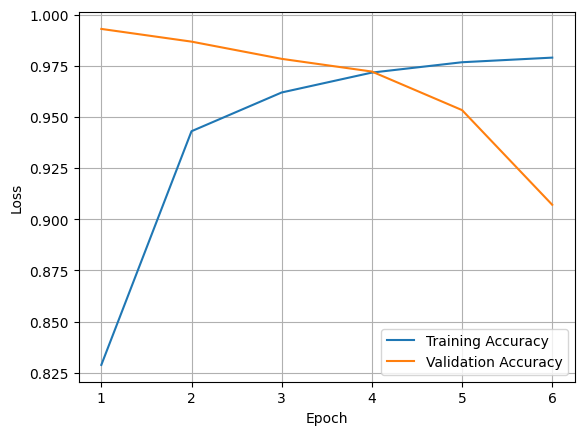

In [ ]:
#Store the model accuracy history
dict_history_model2 = fit_history_model2.history
#Create a range of number coherent with the model's number of epoch
epoch_number = range(1, len(dict_history_model2['accuracy']) + 1)
#Plot the training accuracy
plt.plot(epoch_number, dict_history_model2['accuracy'], label = 'Training Accuracy')
#Plot the validation accuracy
plt.plot(epoch_number, dict_history_model2['val_accuracy'], label = 'Validation Accuracy')
#Create the grid
plt.grid()
#Create the axis' labels
plt.xlabel('Epoch')
plt.ylabel('Loss')
#Show the legend
plt.legend()
#Show the plot
plt.show()


###<b>Evaluating the model

In [ ]:
test_pred_model2 = model2.predict(test_img_data)
test_pred_model2 = np.argmax(test_pred_model2, axis = -1)

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


####<b>Observations and insights: ____



*   The base model show good performance
*   The addition of LeakyRelu add to the performance but not by much
*   The use of BatchNormalization doesn't do much to the model's performance

*   The images from the data are not very complex as within one sample image there is not much color variation and overall the cells' shapes are pretty close to each other, therefore adding in complexity to the model could prove too expensive for the slight rise in performances.

<b> Generate the classification report and confusion matrix

              precision    recall  f1-score   support

           0       0.99      0.85      0.91      1300
           1       0.87      0.99      0.92      1300

    accuracy                           0.92      2600
   macro avg       0.93      0.92      0.92      2600
weighted avg       0.93      0.92      0.92      2600



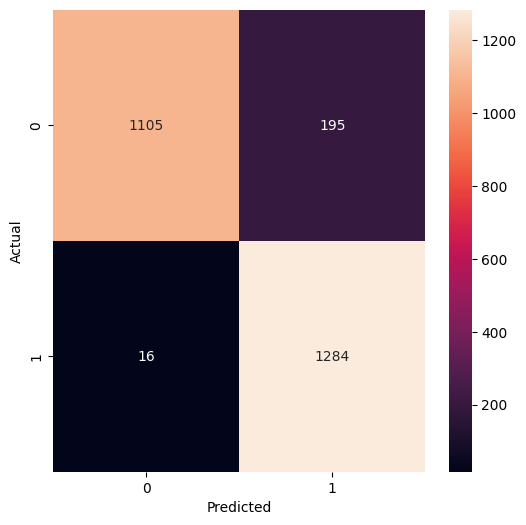

In [ ]:
print(classification_report(np.argmax(test_labels, axis=-1), test_pred_model2))
cm = confusion_matrix(np.argmax(test_labels, axis=-1), test_pred_model2)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot = True,  fmt = 'd',)
#Define the axis' labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
#Show plot
plt.show()

###**Think About It :**<br>

* Can we improve the model with Image Data Augmentation?
* References to image data augmentation can be seen below:
  *   [Image Augmentation for Computer Vision](https://www.mygreatlearning.com/blog/understanding-data-augmentation/)
  *   [How to Configure Image Data Augmentation in Keras?](https://machinelearningmastery.com/how-to-configure-image-data-augmentation-when-training-deep-learning-neural-networks/)





###<b>Model 3 with Data Augmentation

In [ ]:
#Clear memory from previous model
backend.clear_session()

###<b> Use image data generator

In [ ]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#Splitting the data
X_train, X_val, y_train, y_val = train_test_split(training_img_data, training_labels, test_size = 0.2, random_state = 42)
# Using ImageDataGenerator to generate images
train_gen = ImageDataGenerator(horizontal_flip = True, zoom_range = 0.5, rotation_range = 30)
val_gen  = ImageDataGenerator()
# Flowing training images using train_datagen generator
train_generator = train_gen.flow(x = X_train, y = y_train, batch_size = 64, seed = 42, shuffle = True)
# Flowing validation images using val_datagen generator
val_generator =  val_gen.flow(x = X_val, y = y_val, batch_size = 64, seed = 42, shuffle = True)

###**Think About It :**<br>

*  Check if the performance of the model can be improved by changing different parameters in the ImageDataGenerator.



####<B>Visualizing Augmented images

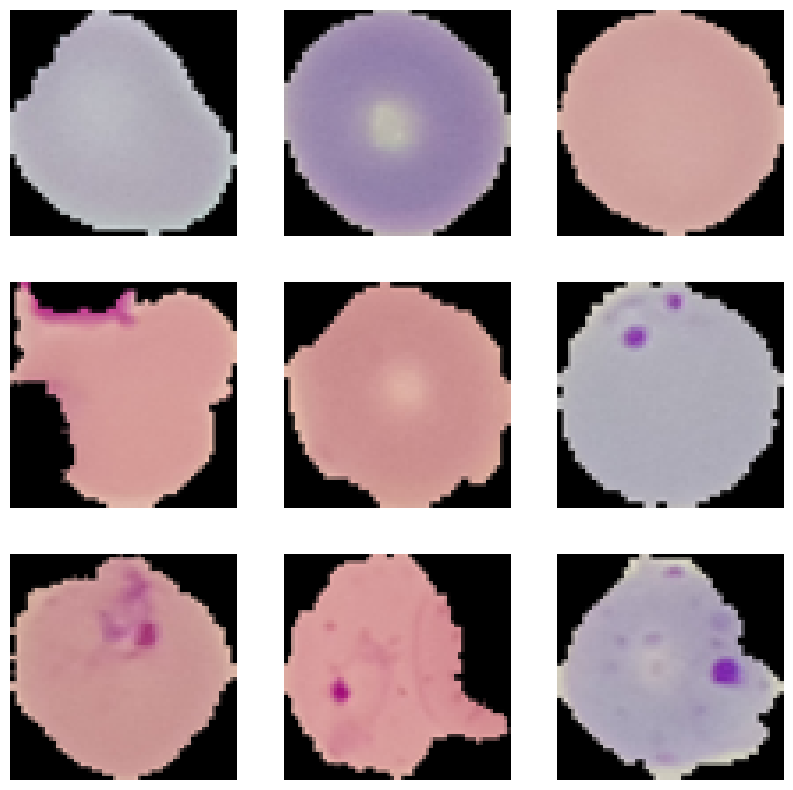

In [ ]:
#Generate samples and plot
plt.figure(figsize=(10, 10))
for i in range(9):
	# define subplot
	plt.subplot(330 + 1 + i)
	# generate batch of images
	batch = next(val_generator)
	# convert to unsigned integers for viewing
	image = batch[0][0] # Select the first image from the batch
	# plot raw pixel data
	plt.imshow(image)
	plt.axis('off')
# show the figure
plt.show()

###<b>Building the Model

In [ ]:
#Create an instance of the model
aug_model1 = Sequential()
#First convolution layer
aug_model1.add(Conv2D(16, (3, 3), input_shape=(64, 64, 3)))
#LeakyRelu activation
aug_model1.add(LeakyReLU(alpha=0.1))
#Normalization layer
aug_model1.add(BatchNormalization())
#Dropout
aug_model1.add(Dropout(0.2))
#Second convolution layer
aug_model1.add(Conv2D(8, (3, 3), input_shape=(64, 64, 3)))
#LeakyRelu activation
aug_model1.add(LeakyReLU(alpha=0.1))
#Normalization layer
aug_model1.add(BatchNormalization())
#Third convolution layer
aug_model1.add(Conv2D(4, (3, 3), input_shape=(64, 64, 3)))
#LeakyRelu activation
aug_model1.add(LeakyReLU(alpha=0.1))
#Max Pooling layer
aug_model1.add(MaxPooling2D(pool_size=(2, 2)))
#Reshape data for dense layer
aug_model1.add(Flatten())


#Dense Network
#First dense layer
aug_model1.add(Dense(32))
#LeakyRelu activation
aug_model1.add(LeakyReLU(alpha=0.1))
#Second dense layer
aug_model1.add(Dense(16))
#LeakyRelu activation
aug_model1.add(LeakyReLU(alpha=0.1))
#Output layer
aug_model1.add(Dense(2, activation='softmax'))

aug_model1.compile(optimizer=Adam(learning_rate = 0.001), loss='categorical_crossentropy', metrics=['accuracy'])

<b>Using Callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 2),
             ModelCheckpoint('best_model.keras', monitor = 'val_loss', save_best_only = True)]

<b> Fit and Train the model

In [ ]:
#Print the model's summary
aug_model1.summary()
#Fit the model
fit_history_aug_model1 = aug_model1.fit(train_generator, epochs=20, batch_size=64, callbacks=callbacks, validation_data=val_generator)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 62, 62, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 62, 62, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 62, 62, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 60, 60, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 60, 60, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 60, 60, 8)      │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 58, 58, 4)      │           292 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 58, 58, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 29, 29, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3364)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       107,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,238 (430.62 KB)

 Trainable params: 110,190 (430.43 KB)

 Non-trainable params: 48 (192.00 B)

Epoch 1/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 33s 91ms/step - accuracy: 0.6182 - loss: 0.7205 - val_accuracy: 0.5787 - val_loss: 0.6872
Epoch 2/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 25s 79ms/step - accuracy: 0.8200 - loss: 0.4294 - val_accuracy: 0.8373 - val_loss: 0.5729
Epoch 3/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 26s 82ms/step - accuracy: 0.8865 - loss: 0.2866 - val_accuracy: 0.9261 - val_loss: 0.1911
Epoch 4/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 25s 80ms/step - accuracy: 0.8993 - loss: 0.2502 - val_accuracy: 0.9481 - val_loss: 0.1578
Epoch 5/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 25s 81ms/step - accuracy: 0.9154 - loss: 0.2304 - val_accuracy: 0.9461 - val_loss: 0.1635
Epoch 6/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 25s 80ms/step - accuracy: 0.9249 - loss: 0.2151 - val_accuracy: 0.9241 - val_loss: 0.3083


###<B>Evaluating the model

<b>Plot the train and validation accuracy

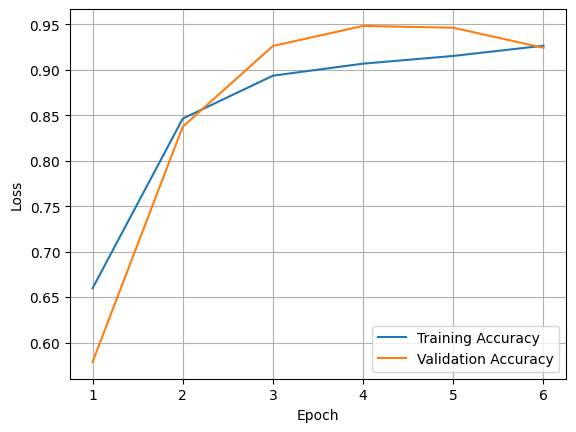

In [ ]:
#Store the model history
dict_history_aug_model1 = fit_history_aug_model1.history
#Create a range of value regarding the number of epoch of the model
epoch_number = range(1, len(dict_history_aug_model1['accuracy']) + 1)
#Plot training accuracy
plt.plot(epoch_number, dict_history_aug_model1['accuracy'], label = 'Training Accuracy')
#Plot validation accuracy
plt.plot(epoch_number, dict_history_aug_model1['val_accuracy'], label = 'Validation Accuracy')
#Create a grid for better value reading
plt.grid()
#Create axis' label
plt.xlabel('Epoch')
plt.ylabel('Loss')
#Create legend
plt.legend()
#Show plot
plt.show()

<B>Plotting the classification report and confusion matrix

In [ ]:
test_pred_aug_model1 = aug_model1.predict(test_img_data)
test_pred_aug_model1 = np.argmax(test_pred_aug_model1, axis = -1)

82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step


              precision    recall  f1-score   support

           0       0.89      1.00      0.94      1300
           1       1.00      0.87      0.93      1300

    accuracy                           0.93      2600
   macro avg       0.94      0.93      0.93      2600
weighted avg       0.94      0.93      0.93      2600



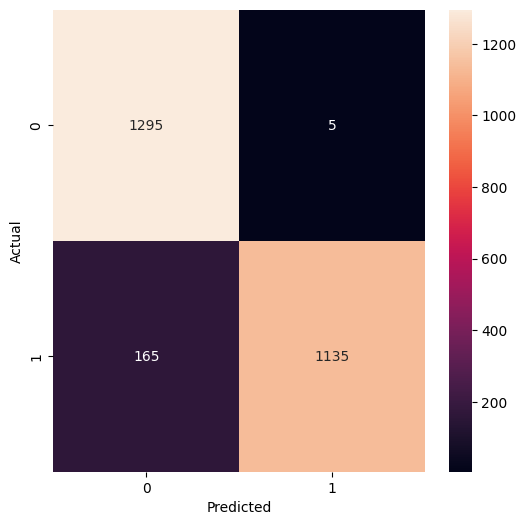

In [ ]:
#Print model's performance metrics
print(classification_report(np.argmax(test_labels, axis=-1), test_pred_aug_model1))
#Compute confusion matrix
cm = confusion_matrix(np.argmax(test_labels, axis=-1), test_pred_aug_model1)
#Define plot size
plt.figure(figsize=(6, 6))
#Plot the confusion matrix
sns.heatmap(cm, annot = True,  fmt = 'd',)
#Define the axis' labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
#Show plot
plt.show()

####<b>Observations and insights: ____

*   The data augmentation does not add much to the performance
*   The model using data augmentation is now underfitting while the previous models seemed more balanced regarding overfitting and underfitting
*   **The parameters used could proove ineficient for some reasons:**

      1. The circular shapes of the cells: the random rotation used would not add much to the variety of images, the same can be said about horizontal shift
      2. The position shift could be detrimental to the data pushing significant features out of the frame
      3. The simplicity of the color schemes does not permit to generate significant variations using brighness or saturation modification

*    A better approach could be to change hue and/or saturation
*    The use of the converted data to hsv could prove as usefull     

###<b> Additional Model 1
####<b> Trying to improve the performance with more complex model


In [ ]:
backend.clear_session()

###<b> Building the Model

In [ ]:
#Create an instance of the model
add_model1 = Sequential()
#First convolution layer
add_model1.add(Conv2D(128, (3, 3), input_shape=(64, 64, 3)))
#LeakyRelu activation
add_model1.add(LeakyReLU(alpha=0.1))
#Dropout
add_model1.add(Dropout(0.2))
#Second convolution layer
add_model1.add(Conv2D(64, (3, 3)))
#LeakyRelu activation
add_model1.add(LeakyReLU(alpha=0.1))
#Third convolution layer
add_model1.add(Conv2D(32, (3, 3)))
#LeakyRelu activation
add_model1.add(LeakyReLU(alpha=0.1))
#Fourth convolution layer
add_model1.add(Conv2D(16, (3, 3)))
#LeakyRelu activation
add_model1.add(LeakyReLU(alpha=0.1))
#Fith convolution layer
add_model1.add(Conv2D(8, (3, 3)))
#LeakyRelu activation
add_model1.add(LeakyReLU(alpha=0.1))
#Max Pooling layer
add_model1.add(MaxPooling2D(pool_size=(2, 2)))
#Reshape data for dense layer
add_model1.add(Flatten())

#Dense Network
#First dense layer
add_model1.add(Dense(32, activation='relu'))
#Second dense layer
add_model1.add(Dense(16, activation='relu'))
#Output layer
add_model1.add(Dense(2, activation='softmax'))

###<b> Compiling the model

In [ ]:
add_model1.compile(optimizer=Adam(learning_rate = 0.001), loss='categorical_crossentropy', metrics=['accuracy'])

<b> Using Callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 2),
             ModelCheckpoint('best_model.keras', monitor = 'val_loss', save_best_only = True)]

<b>Fit and Train the model

In [ ]:
#Print model's summary
add_model1.summary()
#Fit the model
fit_history_add_model1 = add_model1.fit(training_img_data, training_labels, validation_split=0.2, verbose=1, epochs=20, batch_size=64, callbacks=callbacks)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 128)    │         3,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 62, 62, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 62, 62, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 60, 60, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 60, 60, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 58, 58, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 58, 58, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 56, 56, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 56, 56, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 54, 54, 8)      │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 54, 54, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 27, 27, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5832)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       186,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 288,842 (1.10 MB)

 Trainable params: 288,842 (1.10 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 33s 77ms/step - accuracy: 0.7095 - loss: 0.5470 - val_accuracy: 0.9673 - val_loss: 0.1010
Epoch 2/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.9503 - loss: 0.1461 - val_accuracy: 0.9846 - val_loss: 0.0708
Epoch 3/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.9663 - loss: 0.1017 - val_accuracy: 0.9838 - val_loss: 0.0595
Epoch 4/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 15s 49ms/step - accuracy: 0.9782 - loss: 0.0700 - val_accuracy: 0.9818 - val_loss: 0.0601
Epoch 5/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 15s 48ms/step - accuracy: 0.9807 - loss: 0.0572 - val_accuracy: 0.9657 - val_loss: 0.1187


###<b> Evaluating the model

In [ ]:
test_pred_add_model1 = add_model1.predict(test_img_data)
test_pred_add_model1 = np.argmax(test_pred_add_model1, axis = -1)

82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step


<b> Plotting the confusion matrix

              precision    recall  f1-score   support

           0       0.99      0.96      0.98      1300
           1       0.96      0.99      0.98      1300

    accuracy                           0.98      2600
   macro avg       0.98      0.98      0.98      2600
weighted avg       0.98      0.98      0.98      2600



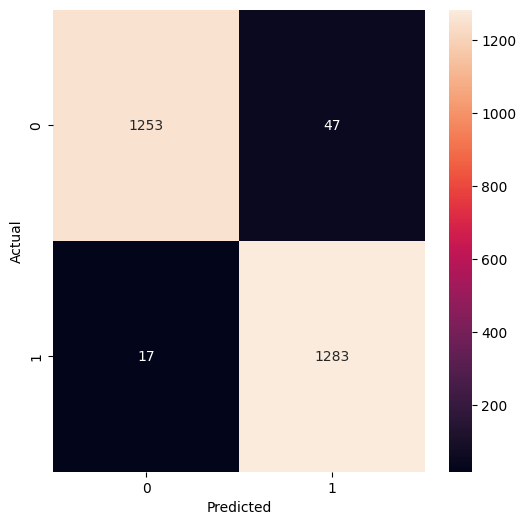

In [ ]:
#Print the classification report
print(classification_report(np.argmax(test_labels, axis=-1), test_pred_add_model1))
#Compute the confusion matrix
cm = confusion_matrix(np.argmax(test_labels, axis=-1), test_pred_add_model1)
#Define the plot size
plt.figure(figsize=(6, 6))
#Plot the confusion matrix
sns.heatmap(cm, annot = True,  fmt = 'd',)
#Define the axis' labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
#Show plot
plt.show()

<b> Plotting the train and the validation curves

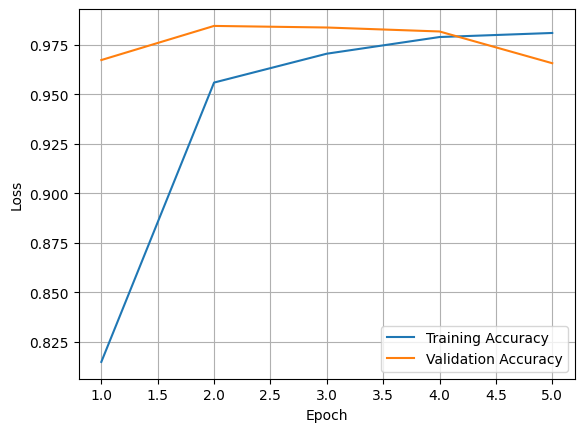

In [ ]:
#Store the model history
dict_history_add_model1 = fit_history_add_model1.history
#Define the x axis range based on the epoch number
epoch_number = range(1, len(dict_history_add_model1['accuracy']) + 1)
#Plot training accuracy
plt.plot(epoch_number, dict_history_add_model1['accuracy'], label = 'Training Accuracy')
#Plot validation accuracy
plt.plot(epoch_number, dict_history_add_model1['val_accuracy'], label = 'Validation Accuracy')
#Show grid
plt.grid()
#Define axis' labels
plt.xlabel('Epoch')
plt.ylabel('Loss')
#Show legend
plt.legend()
#Show plot
plt.show()

<b> Now, let us try to use a pretrained model like VGG16 and check how it performs on our data.

### **Pre-trained model (VGG16)**
- Import VGG16 network upto any layer you choose
- Add Fully Connected Layers on top of it

In [ ]:
#Clear memory from previous model
backend.clear_session()
#Set seed for reproductability
np.random.seed(42)
import random
random.seed(42)
tf.random.set_seed(42)

###<b>Compiling the model

In [ ]:
#Import the VGG16 model
from tensorflow.keras.applications import VGG16
from tensorflow.keras import Model
#Instanciate the model
vgg = VGG16(include_top=False, weights='imagenet', input_shape=(64, 64, 3))

In [ ]:
transfer_layer = vgg.get_layer('block5_pool')

vgg.trainable = False

dense_layer = Flatten()(transfer_layer.output)
#First dense layer
dense_layer = Dense(64, activation = 'relu')(dense_layer)
#Dropout
dense_layer = Dropout(0.3)(dense_layer)
#Second dense layer
dense_layer = Dense(32, activation = 'relu')(dense_layer)
#Dropout
dense_layer = Dropout(0.3)(dense_layer)
#Normalisation layer
dense_layer = BatchNormalization()(dense_layer)
#Third dense layer
dense_layer = Dense(16, activation='relu')(dense_layer)
#Output layer
out = Dense(2, activation='softmax')(dense_layer)

#Initialize
model_VGG16_1 = Model(vgg.input, out)
#Compile
model_VGG16_1.compile(optimizer=Adam(learning_rate = 0.001), loss='categorical_crossentropy', metrics=['accuracy'])

<b> using callbacks

In [ ]:
callbacks = [EarlyStopping(monitor = 'val_loss', patience = 5),
             ModelCheckpoint('best_model.keras', monitor = 'val_loss', save_best_only = True)]

<b>Fit and Train the model

In [ ]:
tf.config.run_functions_eagerly(True)
model_VGG16_1.summary()
fit_history_model_VGG16_1 = model_VGG16_1.fit(training_img_data, training_labels, epochs=20, batch_size=64, callbacks=callbacks, validation_split=0.2)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 64, 64, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 8, 8, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 8, 8, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           12

 Total params: 14,848,594 (56.64 MB)

 Trainable params: 133,842 (522.82 KB)

 Non-trainable params: 14,714,752 (56.13 MB)

Epoch 1/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 59s 169ms/step - accuracy: 0.7780 - loss: 0.4433 - val_accuracy: 0.9539 - val_loss: 0.1729
Epoch 2/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 48s 154ms/step - accuracy: 0.9092 - loss: 0.2178 - val_accuracy: 0.9790 - val_loss: 0.0820
Epoch 3/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 52s 165ms/step - accuracy: 0.9175 - loss: 0.2083 - val_accuracy: 0.9854 - val_loss: 0.1154
Epoch 4/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 55s 177ms/step - accuracy: 0.9263 - loss: 0.1848 - val_accuracy: 0.9760 - val_loss: 0.1047
Epoch 5/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 61s 194ms/step - accuracy: 0.9332 - loss: 0.1708 - val_accuracy: 0.9854 - val_loss: 0.1062
Epoch 6/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 54s 172ms/step - accuracy: 0.9343 - loss: 0.1701 - val_accuracy: 0.9724 - val_loss: 0.1181
Epoch 7/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 56s 178ms/step - accuracy: 0.9332 - loss: 0.1730 - val_accuracy: 0.9808 - val_loss: 0.0637
Epoch 8/20
312/312 ━━━━━━━━━━━━━━━━━━━━ 60s 193ms/step - accuracy: 0.9437 - loss: 0

<b>Plot the train and validation accuracy

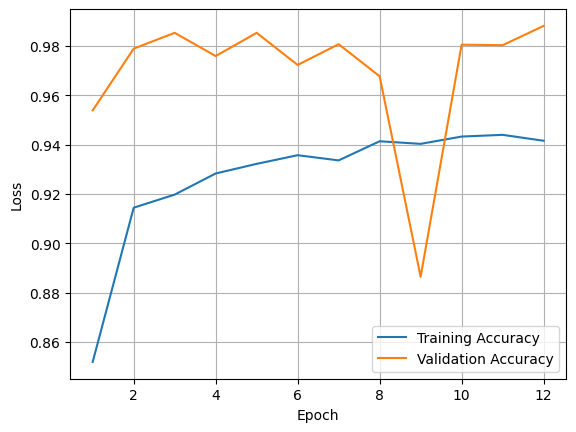

In [ ]:
#Store model's dictionnary
dict_history_model_VGG16_1 = fit_history_model_VGG16_1.history
#Range for the X axis based on number of epoch
epoch_number = range(1, len(dict_history_model_VGG16_1['accuracy']) + 1)
#Plot training accuracy
plt.plot(epoch_number, dict_history_model_VGG16_1['accuracy'], label = 'Training Accuracy')
#Plot validation accuracy
plt.plot(epoch_number, dict_history_model_VGG16_1['val_accuracy'], label = 'Validation Accuracy')
#Show grid
plt.grid()
#Define labels
plt.xlabel('Epoch')
plt.ylabel('Loss')
#Show legend
plt.legend()
#Show image
plt.show()

###**Observations and insights: _____**

*   The validation accuracy is higher than the training accuracy
*   The model is underfitting

###<b> Evaluating the model

In [ ]:
test_pred_model_VGG16_1 = model_VGG16_1.predict(test_img_data)
test_pred_model_VGG16_1 = np.argmax(test_pred_model_VGG16_1, axis = -1)

82/82 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step


<b>Plotting the classification report and confusion matrix

              precision    recall  f1-score   support

           0       0.92      0.98      0.95      1300
           1       0.98      0.91      0.94      1300

    accuracy                           0.95      2600
   macro avg       0.95      0.95      0.95      2600
weighted avg       0.95      0.95      0.95      2600



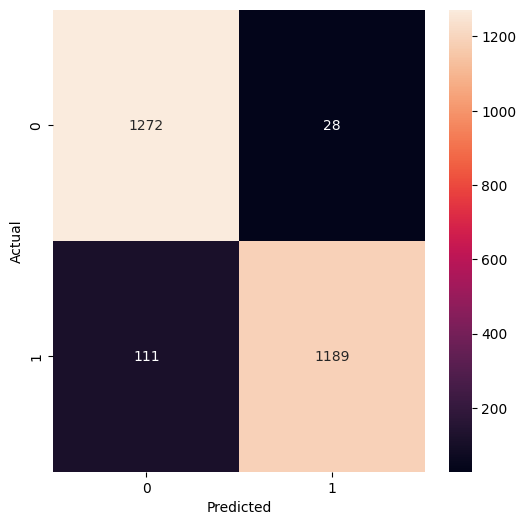

In [ ]:
print(classification_report(np.argmax(test_labels, axis=-1), test_pred_model_VGG16_1))
cm = confusion_matrix(np.argmax(test_labels, axis=-1), test_pred_model_VGG16_1)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot = True,  fmt = 'd',)
#Define the axis' labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
#Show plot
plt.show()

###<b>Think about it:</b>
*  What observations and insights can be drawn from the confusion matrix and classification report?

        1.   Model's performance are not significantly higher
        2.   There is still a lot of False Negative wich is not ideal for medical purpose
        3.   Recall is scoring higher for the uninfected cells while Precision is scoring higher for the parasatized cells

*  Choose the model with the best accuracy scores from all the above models and save it as a final model.


        *   add_model1 is so far the one with the best performances with the best overall F1 score and Recall






####<b> Observations and Conclusions drawn from the final model: _____



**Improvements that can be done:**<br>


*  Can the model performance be improved using other pre-trained models or different CNN architecture?

        1. The tests done with multiple models of various complexity prooved the pre-trained model VGG16 more costly without significant improvement.
        2. Adding layers to the add_model1 like more Dropout layers
        could improve but the performance so far seems good enough,
        further test may be interesting



*  You can try to build a model using these HSV images and compare them with your other models.

#### **Insights**

####**Refined insights**:
*  Complex model can be detrimental to the task intended when data
*   Testing the models with a lower image resolution could be interesting as there is two main differences between test and training data: shapes and color. Therefore even if lowering the resolution of the data might get rid of some shapes, the models could still perform well on the color aspect

####**Comparison of various techniques and their relative performance**:
*   Simple data augmentation model didn't show any notable increase in performances
*   Basic architecture scored high but with a more complex one performances are even higher.
*   Batch Normalization didn't help much
*   LeakyRelu activation method had a noticeable impact
*   Dropout layer setup added to the performance
*   There is still a bit of improvement that can be made but with scores above 97% on all metrics add_model1 is sufficiently good


####**Proposal for the final solution design**:

*   The last model made from scratch (add_model1) is the best one so far balancing computational cost with good performances, especially on Recall. As the data is not very complicated more complex models would be too long for not much improvement as seen with the VGG16 model and the Recall wich is a better metrics for medical imagery as it compare the true predicted to the actual
true. Performances is not the only goal of such model.